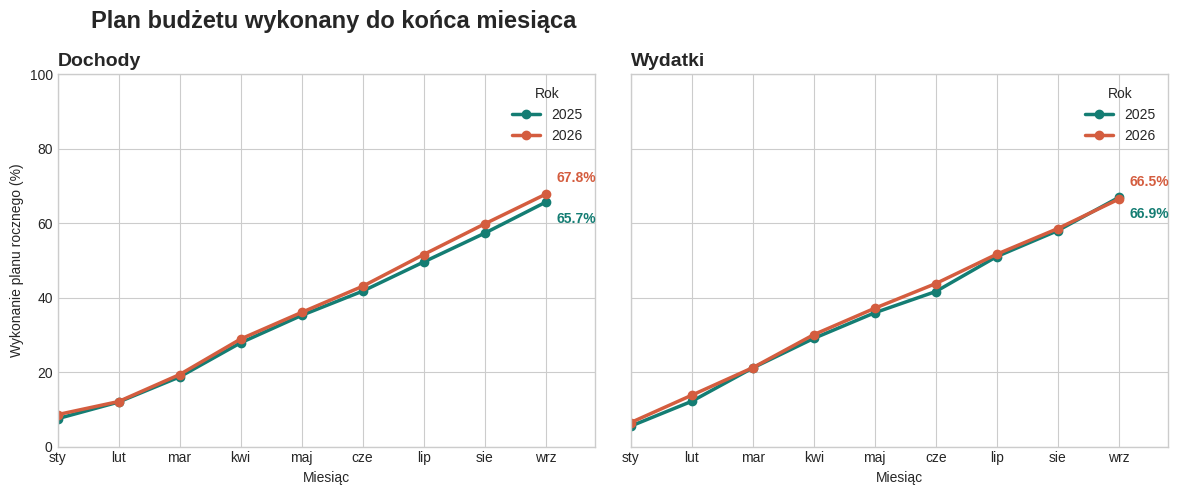

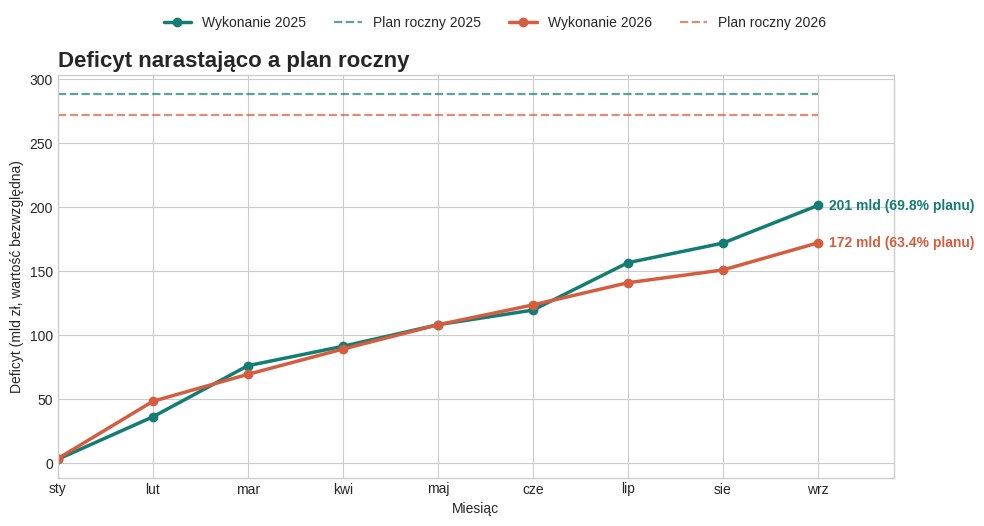

,Rok,Miesiąc,Dochody (% planu),Wydatki (% planu),Deficyt (mld zł),Deficyt (% planu)
0,2025,9,65.7,66.9,201.4,69.8
1,2026,9,67.8,66.5,172.2,63.4


In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PLOT_DIR = Path("img")
PLOT_DIR.mkdir(exist_ok=True)

budget_2025 = pd.read_csv(Path("data_2025") / "budzet_panstwa_2025.csv")
budget_2026 = pd.read_csv(Path("data_2026") / "budzet_panstwa_2026.csv")
data = pd.concat([budget_2025, budget_2026], ignore_index=True)
data["lp"] = data["lp"].fillna("").astype(str)

months_2025 = set(budget_2025["miesiac"].dropna().astype(int))
months_2026 = set(budget_2026["miesiac"].dropna().astype(int))
months = sorted(months_2025 & months_2026)
assert months == list(range(1, 10)), f"Nieoczekiwany wspólny zakres miesięcy: {months}"
common_data = data[data["miesiac"].isin(months)]

month_names = ["sty", "lut", "mar", "kwi", "maj", "cze", "lip", "sie", "wrz"]
year_colors = {2025: "#147D73", 2026: "#D45D3F"}
plt.style.use("seaborn-v0_8-whitegrid")

# Wykres 1: tempo realizacji dochodów i wydatków względem planu rocznego.
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, code, title in zip(axes, ["1", "2"], ["Dochody", "Wydatki"]):
    subset = common_data[common_data["lp"] == code]
    for year in [2025, 2026]:
        series = subset[subset["rok"] == year].sort_values("miesiac")
        progress = series["wykonanie"] / series["ustawa"] * 100
        ax.plot(series["miesiac"], progress, marker="o", linewidth=2.5,
                color=year_colors[year], label=str(year))
        ax.annotate(f"{progress.iloc[-1]:.1f}%",
                    (series["miesiac"].iloc[-1], progress.iloc[-1]),
                    xytext=(8, -12 if year == 2025 else 12), textcoords="offset points",
                    va="center", color=year_colors[year], fontweight="bold")
    ax.set_title(title, loc="left", fontsize=14, fontweight="bold")
    ax.set_xticks(months, month_names)
    ax.set_xlim(1, 9.8)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Miesiąc")
    ax.legend(title="Rok", frameon=False)
axes[0].set_ylabel("Wykonanie planu rocznego (%)")
fig.suptitle("Plan budżetu wykonany do końca miesiąca", fontsize=17, fontweight="bold", x=0.08, ha="left")
fig.tight_layout()
fig.savefig(PLOT_DIR / "plan_wykonanie_dochody_wydatki_2025_2026.png", dpi=180, bbox_inches="tight")
plt.show()

# Wykres 2: narastający deficyt i plan roczny; wartości pokazane bez znaku.
deficit = common_data[common_data["lp"] == "3"].copy()
fig, ax = plt.subplots(figsize=(10, 5.5))
summary_rows = []
for year in [2025, 2026]:
    series = deficit[deficit["rok"] == year].sort_values("miesiac")
    plan_bln = series["ustawa"].abs() / 1000
    actual_bln = series["wykonanie"].abs() / 1000
    color = year_colors[year]
    ax.plot(series["miesiac"], actual_bln, marker="o", linewidth=2.5,
            color=color, label=f"Wykonanie {year}")
    ax.plot(series["miesiac"], plan_bln, linestyle="--", linewidth=1.6,
            color=color, alpha=0.7, label=f"Plan roczny {year}")
    final_actual = actual_bln.iloc[-1]
    final_plan = plan_bln.iloc[-1]
    share = final_actual / final_plan * 100
    ax.annotate(f"{final_actual:.0f} mld ({share:.1f}% planu)",
                (series["miesiac"].iloc[-1], final_actual), xytext=(8, 0),
                textcoords="offset points", va="center", color=color, fontweight="bold")
    last_month = common_data[(common_data["rok"] == year) & (common_data["miesiac"] == months[-1])]
    revenue = last_month[last_month["lp"] == "1"].iloc[0]
    expenditure = last_month[last_month["lp"] == "2"].iloc[0]
    summary_rows.append({"Rok": year, "Miesiąc": months[-1],
                         "Dochody (% planu)": revenue["wykonanie"] / revenue["ustawa"] * 100,
                         "Wydatki (% planu)": expenditure["wykonanie"] / expenditure["ustawa"] * 100,
                         "Deficyt (mld zł)": final_actual,
                         "Deficyt (% planu)": share})

ax.set_title("Deficyt narastająco a plan roczny", loc="left", fontsize=16, fontweight="bold")
ax.set_xlabel("Miesiąc")
ax.set_ylabel("Deficyt (mld zł, wartość bezwzględna)")
ax.set_xticks(months, month_names)
ax.set_xlim(1, 9.8)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 0.96))
fig.tight_layout(rect=[0, 0, 1, 0.9])
fig.savefig(PLOT_DIR / "deficyt_plan_wykonanie_2025_2026.png", dpi=180, bbox_inches="tight")
plt.show()

display(pd.DataFrame(summary_rows).round(1))

# Budżet 2025: analiza całego roku

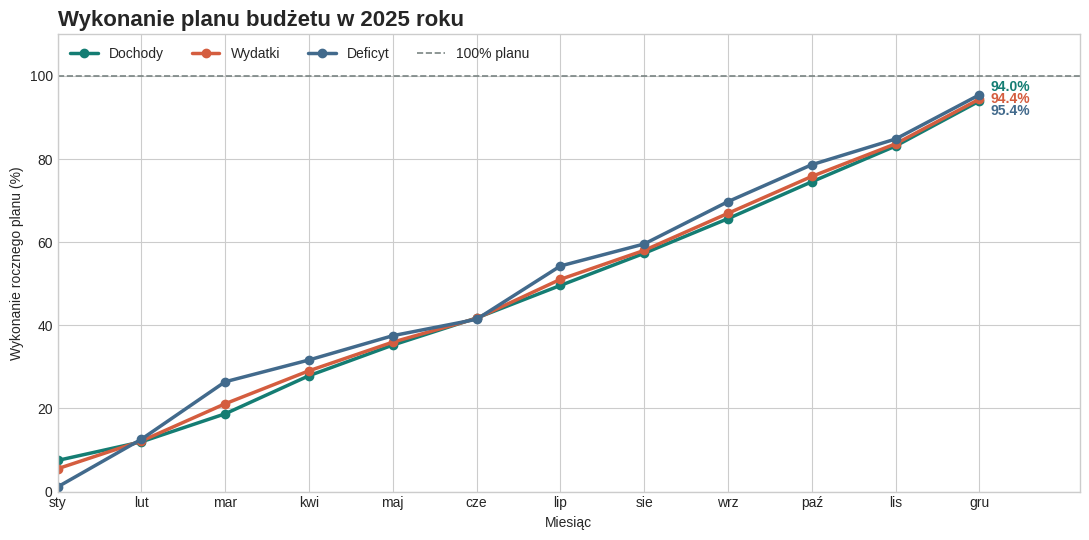

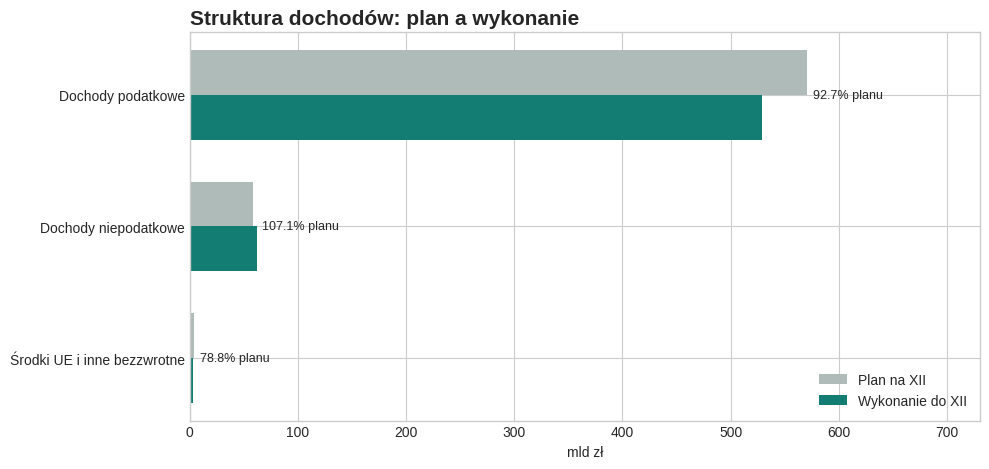

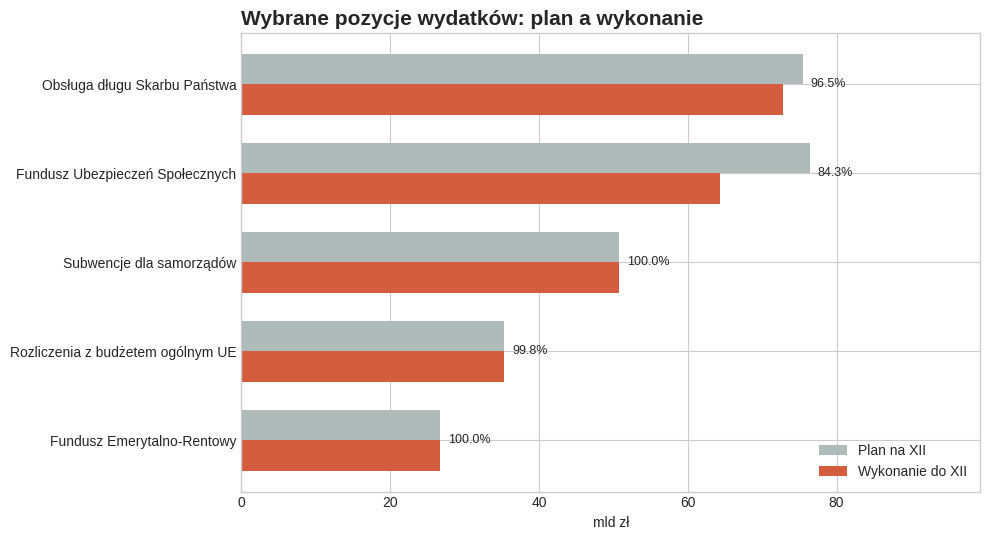

,Pozycja,Plan roczny (mld zł),Wykonanie (mld zł),Wykonanie planu (%)
0,Dochody,632.8,594.6,94.0
1,Wydatki,921.6,870.2,94.4
2,Deficyt,288.8,275.6,95.4


In [4]:
import numpy as np

budget_2025 = pd.read_csv(Path("data_2025") / "budzet_panstwa_2025.csv")
budget_2025["nr"] = budget_2025["nr"].astype(int)
december = budget_2025[budget_2025["miesiac"] == 12].set_index("nr")
months = list(range(1, 13))
month_names = ["sty", "lut", "mar", "kwi", "maj", "cze", "lip", "sie", "wrz", "paź", "lis", "gru"]
actual_color = "#147D73"
plan_color = "#AEBBB8"

# Potwierdzenie, że trzy główne grupy dochodów nie nakładają się i sumują do dochodów ogółem.
income_groups = december.loc[[2, 8, 10]].copy()
assert np.isclose(income_groups["wykonanie"].sum(), december.loc[1, "wykonanie"])

# 1. Miesięczne tempo wykonania planu; wykonanie jest narastające.
fig, ax = plt.subplots(figsize=(11, 5.5))
main_rows = {1: "Dochody", 13: "Wydatki", 19: "Deficyt"}
colors = {1: "#147D73", 13: "#D45D3F", 19: "#426A8C"}
for row_number, label in main_rows.items():
    series = budget_2025[budget_2025["nr"] == row_number].sort_values("miesiac")
    progress = series["wykonanie"].abs() / series["ustawa"].abs() * 100
    ax.plot(series["miesiac"], progress, marker="o", linewidth=2.5,
            color=colors[row_number], label=label)
    ax.annotate(f"{progress.iloc[-1]:.1f}%", (12, progress.iloc[-1]),
                xytext=(8, {1: 10, 13: 0, 19: -12}[row_number]),
                textcoords="offset points", va="center", color=colors[row_number],
                fontweight="bold")
ax.axhline(100, color="#7A8583", linestyle="--", linewidth=1.2, label="100% planu")
ax.set_title("Wykonanie planu budżetu w 2025 roku", loc="left", fontsize=16, fontweight="bold")
ax.set_xlabel("Miesiąc")
ax.set_ylabel("Wykonanie rocznego planu (%)")
ax.set_xticks(months, month_names)
ax.set_xlim(1, 13.2)
ax.set_ylim(0, 110)
ax.legend(frameon=False, ncol=4, loc="upper left")
fig.tight_layout()
fig.savefig(PLOT_DIR / "budzet_2025_tempo_wykonania.png", dpi=180, bbox_inches="tight")
plt.show()

# 2. Dochody według trzech rozłącznych grup: plan i wykonanie na koniec roku.
income_labels = {
    2: "Dochody podatkowe",
    8: "Dochody niepodatkowe",
    10: "Środki UE i inne bezzwrotne",
}
income_groups["etykieta"] = [income_labels[i] for i in income_groups.index]
income_groups = income_groups.iloc[::-1]
y = np.arange(len(income_groups))
bar_height = 0.34
fig, ax = plt.subplots(figsize=(10, 4.8))
plan_values = income_groups["ustawa"] / 1000
actual_values = income_groups["wykonanie"] / 1000
ax.barh(y + bar_height / 2, plan_values, height=bar_height,
        color=plan_color, label="Plan na XII")
ax.barh(y - bar_height / 2, actual_values, height=bar_height,
        color=actual_color, label="Wykonanie do XII")
for i, (_, row) in enumerate(income_groups.iterrows()):
    ratio = row["wykonanie"] / row["ustawa"] * 100
    ax.text(max(row["ustawa"], row["wykonanie"]) / 1000 + 5, i,
            f"{ratio:.1f}% planu", va="center", fontsize=9)
ax.set_yticks(y, income_groups["etykieta"])
ax.set_xlabel("mld zł")
ax.set_title("Struktura dochodów: plan a wykonanie", loc="left", fontsize=15, fontweight="bold")
ax.set_xlim(0, max(plan_values.max(), actual_values.max()) * 1.28)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(PLOT_DIR / "budzet_2025_struktura_dochodow.png", dpi=180, bbox_inches="tight")
plt.show()

# 3. Wybrane pozycje wydatków wyszczególnione w raporcie; nie jest to pełna struktura wydatków.
spending_labels = {
    14: "Obsługa długu Skarbu Państwa",
    15: "Rozliczenia z budżetem ogólnym UE",
    16: "Fundusz Emerytalno-Rentowy",
    17: "Fundusz Ubezpieczeń Społecznych",
    18: "Subwencje dla samorządów",
}
selected_spending = december.loc[list(spending_labels)].copy()
selected_spending["etykieta"] = [spending_labels[i] for i in selected_spending.index]
selected_spending = selected_spending.sort_values("wykonanie")
y = np.arange(len(selected_spending))
fig, ax = plt.subplots(figsize=(10, 5.5))
plan_values = selected_spending["ustawa"] / 1000
actual_values = selected_spending["wykonanie"] / 1000
ax.barh(y + bar_height / 2, plan_values, height=bar_height,
        color=plan_color, label="Plan na XII")
ax.barh(y - bar_height / 2, actual_values, height=bar_height,
        color="#D45D3F", label="Wykonanie do XII")
for i, (_, row) in enumerate(selected_spending.iterrows()):
    ratio = row["wykonanie"] / row["ustawa"] * 100
    ax.text(max(row["ustawa"], row["wykonanie"]) / 1000 + 1, i,
            f"{ratio:.1f}%", va="center", fontsize=9)
ax.set_yticks(y, selected_spending["etykieta"])
ax.set_xlabel("mld zł")
ax.set_title("Wybrane pozycje wydatków: plan a wykonanie", loc="left", fontsize=15, fontweight="bold")
ax.set_xlim(0, max(plan_values.max(), actual_values.max()) * 1.3)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(PLOT_DIR / "budzet_2025_wybrane_wydatki.png", dpi=180, bbox_inches="tight")
plt.show()

headline = []
for row_number, label in [(1, "Dochody"), (13, "Wydatki"), (19, "Deficyt")]:
    row = december.loc[row_number]
    headline.append({"Pozycja": label,
                     "Plan roczny (mld zł)": abs(row["ustawa"]) / 1000,
                     "Wykonanie (mld zł)": abs(row["wykonanie"]) / 1000,
                     "Wykonanie planu (%)": abs(row["wykonanie"] / row["ustawa"]) * 100})
display(pd.DataFrame(headline).round(1))

# Budżet 2026: wykonanie do września

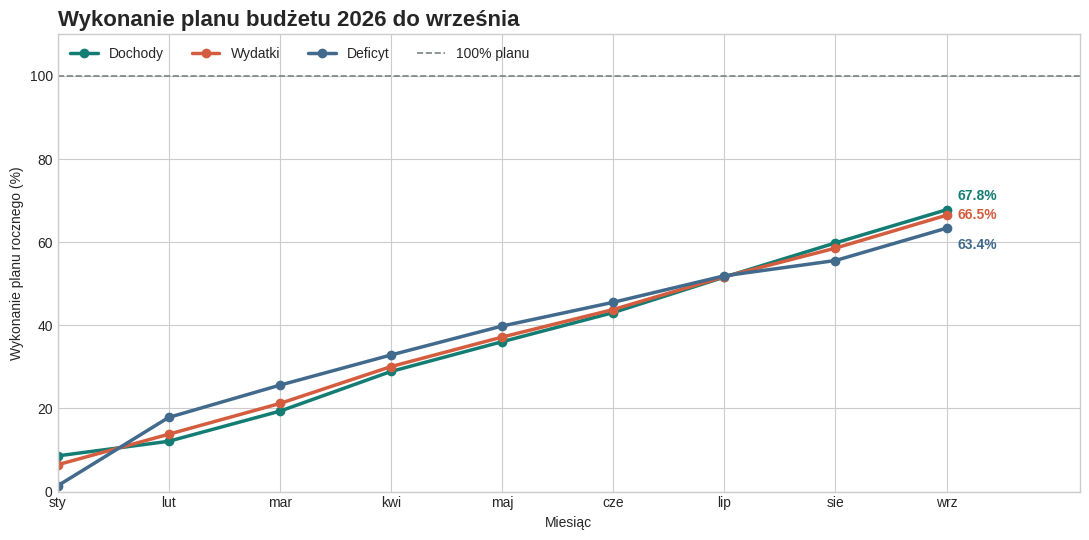

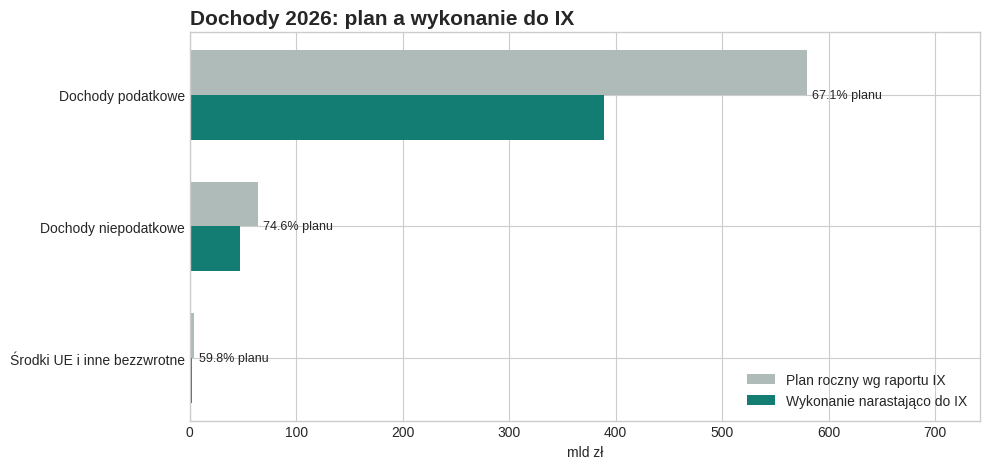

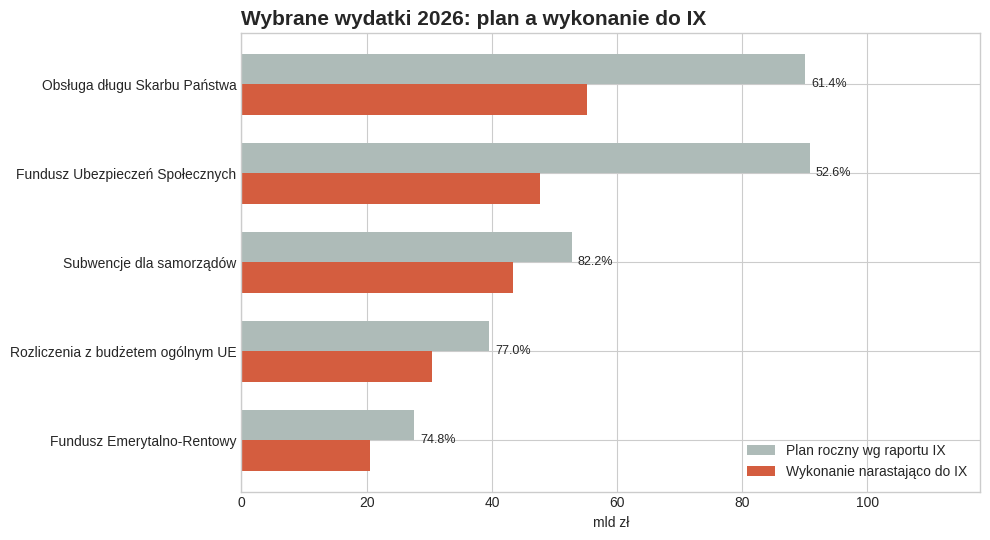

,Pozycja,Plan roczny (mld zł),Wykonanie do IX (mld zł),Wykonanie planu (%)
0,Dochody,647.2,438.8,67.8
1,Wydatki,918.9,611.0,66.5
2,Deficyt,271.7,172.2,63.4


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

budget_2026 = pd.read_csv(Path("data_2026") / "budzet_panstwa_2026.csv")
budget_2026["nr"] = budget_2026["nr"].astype(int)
months_2026 = sorted(budget_2026["miesiac"].dropna().astype(int).unique())
assert months_2026 == list(range(1, 10)), f"Nieoczekiwany zakres miesięcy: {months_2026}"
report_2026 = budget_2026[budget_2026["miesiac"] == months_2026[-1]].set_index("nr")
month_names_2026 = ["sty", "lut", "mar", "kwi", "maj", "cze", "lip", "sie", "wrz"]
plot_dir_2026 = Path("img")
plot_dir_2026.mkdir(exist_ok=True)

income_groups_2026 = report_2026.loc[[2, 8, 10]].copy()
assert np.isclose(income_groups_2026["wykonanie"].sum(), report_2026.loc[1, "wykonanie"])

fig, ax = plt.subplots(figsize=(11, 5.5))
main_rows_2026 = {1: "Dochody", 13: "Wydatki", 19: "Deficyt"}
colors_2026 = {1: "#147D73", 13: "#D45D3F", 19: "#426A8C"}
for row_number, label in main_rows_2026.items():
    series = budget_2026[budget_2026["nr"] == row_number].sort_values("miesiac")
    progress = series["wykonanie"].abs() / series["ustawa"].abs() * 100
    ax.plot(series["miesiac"], progress, marker="o", linewidth=2.5,
            color=colors_2026[row_number], label=label)
    ax.annotate(f"{progress.iloc[-1]:.1f}%", (months_2026[-1], progress.iloc[-1]),
                xytext=(8, {1: 10, 13: 0, 19: -12}[row_number]),
                textcoords="offset points", va="center", color=colors_2026[row_number],
                fontweight="bold")
ax.axhline(100, color="#7A8583", linestyle="--", linewidth=1.2, label="100% planu")
ax.set_title("Wykonanie planu budżetu 2026 do września", loc="left", fontsize=16, fontweight="bold")
ax.set_xlabel("Miesiąc")
ax.set_ylabel("Wykonanie planu rocznego (%)")
ax.set_xticks(months_2026, month_names_2026)
ax.set_xlim(1, 10.2)
ax.set_ylim(0, 110)
ax.legend(frameon=False, ncol=4, loc="upper left")
fig.tight_layout()
fig.savefig(plot_dir_2026 / "budzet_2026_tempo_wykonania_do_IX.png", dpi=180, bbox_inches="tight")
plt.show()

income_labels_2026 = {
    2: "Dochody podatkowe",
    8: "Dochody niepodatkowe",
    10: "Środki UE i inne bezzwrotne",
}
income_groups_2026["etykieta"] = [income_labels_2026[i] for i in income_groups_2026.index]
income_groups_2026 = income_groups_2026.iloc[::-1]
y_2026 = np.arange(len(income_groups_2026))
bar_height_2026 = 0.34
fig, ax = plt.subplots(figsize=(10, 4.8))
plan_values_2026 = income_groups_2026["ustawa"] / 1000
actual_values_2026 = income_groups_2026["wykonanie"] / 1000
ax.barh(y_2026 + bar_height_2026 / 2, plan_values_2026, height=bar_height_2026,
        color="#AEBBB8", label="Plan roczny wg raportu IX")
ax.barh(y_2026 - bar_height_2026 / 2, actual_values_2026, height=bar_height_2026,
        color="#147D73", label="Wykonanie narastająco do IX")
for i, (_, row) in enumerate(income_groups_2026.iterrows()):
    ratio = row["wykonanie"] / row["ustawa"] * 100
    ax.text(max(row["ustawa"], row["wykonanie"]) / 1000 + 5, i,
            f"{ratio:.1f}% planu", va="center", fontsize=9)
ax.set_yticks(y_2026, income_groups_2026["etykieta"])
ax.set_xlabel("mld zł")
ax.set_title("Dochody 2026: plan a wykonanie do IX", loc="left", fontsize=15, fontweight="bold")
ax.set_xlim(0, max(plan_values_2026.max(), actual_values_2026.max()) * 1.28)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(plot_dir_2026 / "budzet_2026_struktura_dochodow_do_IX.png", dpi=180, bbox_inches="tight")
plt.show()

spending_labels_2026 = {
    14: "Obsługa długu Skarbu Państwa",
    15: "Rozliczenia z budżetem ogólnym UE",
    16: "Fundusz Emerytalno-Rentowy",
    17: "Fundusz Ubezpieczeń Społecznych",
    18: "Subwencje dla samorządów",
}
selected_spending_2026 = report_2026.loc[list(spending_labels_2026)].copy()
selected_spending_2026["etykieta"] = [spending_labels_2026[i] for i in selected_spending_2026.index]
selected_spending_2026 = selected_spending_2026.sort_values("wykonanie")
y_2026 = np.arange(len(selected_spending_2026))
fig, ax = plt.subplots(figsize=(10, 5.5))
plan_values_2026 = selected_spending_2026["ustawa"] / 1000
actual_values_2026 = selected_spending_2026["wykonanie"] / 1000
ax.barh(y_2026 + bar_height_2026 / 2, plan_values_2026, height=bar_height_2026,
        color="#AEBBB8", label="Plan roczny wg raportu IX")
ax.barh(y_2026 - bar_height_2026 / 2, actual_values_2026, height=bar_height_2026,
        color="#D45D3F", label="Wykonanie narastająco do IX")
for i, (_, row) in enumerate(selected_spending_2026.iterrows()):
    ratio = row["wykonanie"] / row["ustawa"] * 100
    ax.text(max(row["ustawa"], row["wykonanie"]) / 1000 + 1, i,
            f"{ratio:.1f}%", va="center", fontsize=9)
ax.set_yticks(y_2026, selected_spending_2026["etykieta"])
ax.set_xlabel("mld zł")
ax.set_title("Wybrane wydatki 2026: plan a wykonanie do IX", loc="left", fontsize=15, fontweight="bold")
ax.set_xlim(0, max(plan_values_2026.max(), actual_values_2026.max()) * 1.3)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(plot_dir_2026 / "budzet_2026_wybrane_wydatki_do_IX.png", dpi=180, bbox_inches="tight")
plt.show()

headline_2026 = []
for row_number, label in [(1, "Dochody"), (13, "Wydatki"), (19, "Deficyt")]:
    row = report_2026.loc[row_number]
    headline_2026.append({"Pozycja": label,
                          "Plan roczny (mld zł)": abs(row["ustawa"]) / 1000,
                          "Wykonanie do IX (mld zł)": abs(row["wykonanie"]) / 1000,
                          "Wykonanie planu (%)": abs(row["wykonanie"] / row["ustawa"]) * 100})
display(pd.DataFrame(headline_2026).round(1))

# Struktura wydatków budżetu państwa 2025

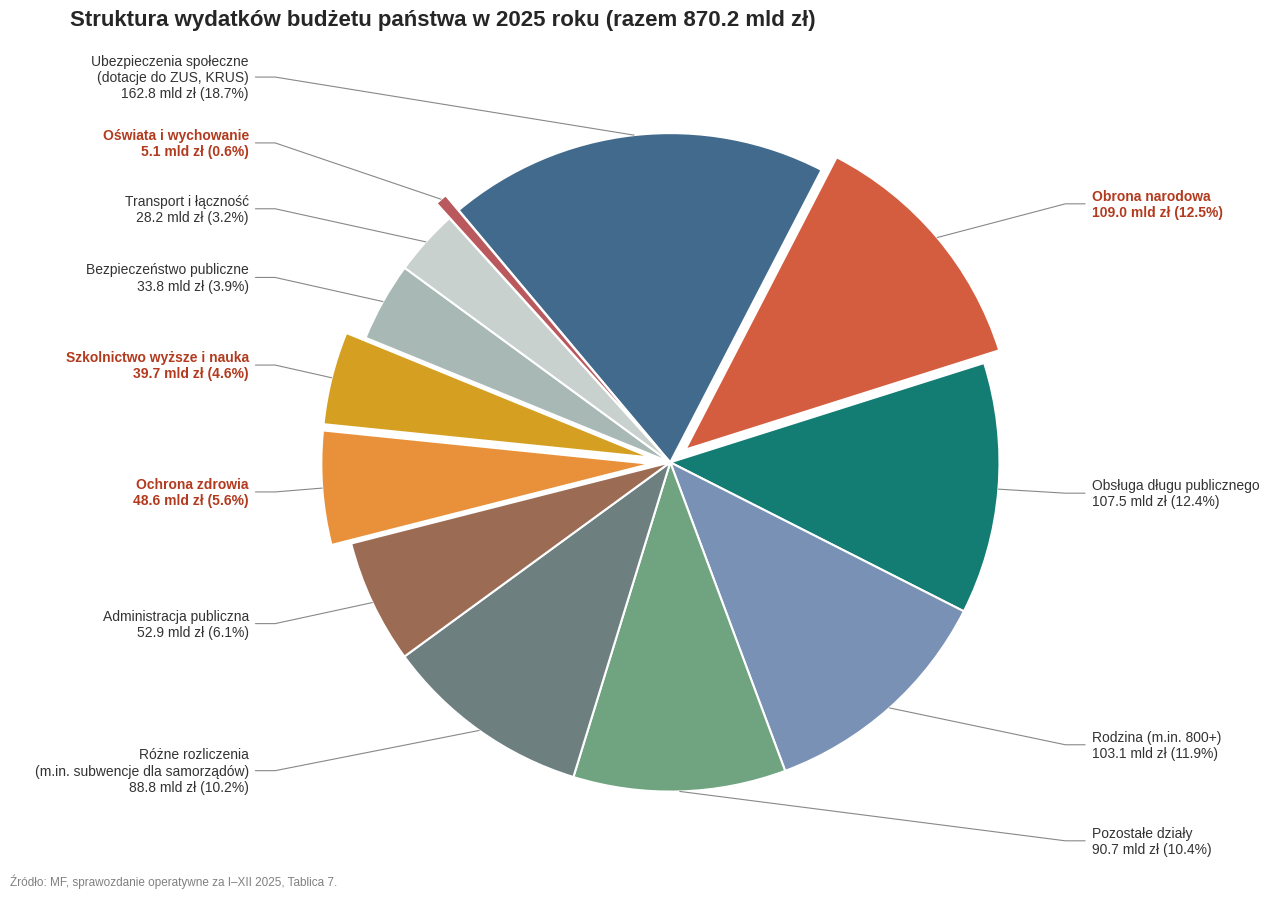

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PLIK = "raw_data_2025/20260601_Sprawozdanie_operatywne_za_styczeń_-_grudzień_2025_r.xlsx"

# 1. Wczytanie TABLICY 7 (wydatki wg działów): a = ustawa, b = plan po zmianach, c = wykonanie (w zł)
raw = pd.read_excel(PLIK, sheet_name="TABLICA 7", header=None)
dzialy, cur = {}, None
for _, r in raw.iterrows():
    typ = str(r[3]).strip()
    if pd.notna(r[2]) and typ == "a":
        cur = str(r[0]).strip()
        dzialy[cur] = {}
    if cur and typ in ("a", "b", "c"):
        dzialy[cur][typ] = r[4] / 1e9          # zł -> mld zł

df = pd.DataFrame(dzialy).T.rename(columns={"a": "ustawa", "b": "po_zmianach", "c": "wykonanie"})
ogolem = df.loc["nan", "wykonanie"]            # wiersz "OGÓŁEM" nie ma numeru działu
df = df.drop(index="nan")
assert abs(df["wykonanie"].sum() - ogolem) < 0.01, "suma działów != wydatki ogółem"

# 2. Nazwy działów pokazywanych osobno (\n = złamanie linii w podpisie)
NAZWY = {
    "753": "Ubezpieczenia społeczne\n(dotacje do ZUS, KRUS)",
    "752": "Obrona narodowa",
    "757": "Obsługa długu publicznego",
    "855": "Rodzina (m.in. 800+)",
    "758": "Różne rozliczenia\n(m.in. subwencje dla samorządów)",
    "750": "Administracja publiczna",
    "851": "Ochrona zdrowia",
    "730": "Szkolnictwo wyższe i nauka",
    "754": "Bezpieczeństwo publiczne",
    "600": "Transport i łączność",
    "801": "Oświata i wychowanie",
}
WYROZNIONE = {NAZWY[k] for k in ("752", "851", "730", "801")}   # obrona, zdrowie, edukacja

czesci = df.loc[list(NAZWY), "wykonanie"]
czesci.index = [NAZWY[k] for k in czesci.index]
czesci["Pozostałe działy"] = df.drop(index=list(NAZWY))["wykonanie"].sum()   # zawsze na końcu
czesci = czesci.sort_values(ascending=False)

# 3. Kolory: wyróżnione obszary w ciepłych barwach, reszta w stonowanych
CIEPLE = iter(["#D45D3F", "#E8913A", "#D5A021", "#B9585D"])
ZIMNE = iter(["#426A8C", "#147D73", "#7991B5", "#70A37F", "#6E7F80", "#9C6B54", "#A7B8B5", "#C9D1CF"])
kolory = [next(CIEPLE) if n in WYROZNIONE else next(ZIMNE) for n in czesci.index]
wysuniecie = [0.06 if n in WYROZNIONE else 0 for n in czesci.index]

# 4. Koło bez legendy i bez procentów w środku (wszystko jest w podpisach na zewnątrz).
#    startangle dobrany tak, żeby małe wycinki wypadły z lewej strony, gdzie jest miejsce na podpisy.
fig, ax = plt.subplots(figsize=(13, 9))
wedges, _ = ax.pie(
    czesci, startangle=130, counterclock=False, colors=kolory, explode=wysuniecie,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)

# 5. Podpisy na zewnątrz z łamanymi liniami prowadzącymi.
podpisy = []
for w, (nazwa, kw) in zip(wedges, czesci.items()):
    kat = np.deg2rad((w.theta1 + w.theta2) / 2)
    przes = 0.06 if nazwa in WYROZNIONE else 0
    x, y = np.cos(kat) * (1 + przes), np.sin(kat) * (1 + przes)   # punkt na brzegu wycinka
    podpisy.append({"nazwa": nazwa, "kw": kw, "x": x, "y": y,
                    "strona": 1 if x >= 0 else -1, "y_tekst": 1.15 * y})

# Rozsuwanie podpisów, żeby na siebie nie nachodziły (osobno z lewej i z prawej).
ODSTEP, Y_MAX = 0.2, 1.25
for strona in (1, -1):
    grupa = sorted([p for p in podpisy if p["strona"] == strona], key=lambda p: p["y_tekst"])
    for _ in range(50):
        for a, b in zip(grupa, grupa[1:]):                      # w górę
            b["y_tekst"] = max(b["y_tekst"], a["y_tekst"] + ODSTEP)
        grupa[-1]["y_tekst"] = min(grupa[-1]["y_tekst"], Y_MAX)
        for a, b in zip(grupa[::-1], grupa[-2::-1]):            # w dół
            b["y_tekst"] = min(b["y_tekst"], a["y_tekst"] - ODSTEP)
        grupa[0]["y_tekst"] = max(grupa[0]["y_tekst"], -Y_MAX)

for p in podpisy:
    wyr = p["nazwa"] in WYROZNIONE
    s = p["strona"]
    x_lamanie, x_tekst = s * 1.2, s * 1.28
    # linia: brzeg wycinka -> załamanie -> poziomo do podpisu
    ax.plot([p["x"], x_lamanie, x_tekst - s * 0.02], [p["y"], p["y_tekst"], p["y_tekst"]],
            color="#888888", lw=0.8)
    ax.text(x_tekst, p["y_tekst"],
            f"{p['nazwa']}\n{p['kw']:.1f} mld zł ({p['kw'] / ogolem * 100:.1f}%)",
            ha="left" if s == 1 else "right", va="center",
            fontsize=10, fontweight="bold" if wyr else "normal",
            color="#B23A1E" if wyr else "#333333")

ax.set_title(f"Struktura wydatków budżetu państwa w 2025 roku (razem {ogolem:.1f} mld zł)",
             loc="left", fontsize=16, fontweight="bold", pad=10)
ax.axis("equal")
fig.text(0.01, 0.01, "Źródło: MF, sprawozdanie operatywne za I–XII 2025, Tablica 7.",
         fontsize=8.5, color="gray")
fig.tight_layout()
fig.savefig(Path("img") / "budzet_2025_kolo_struktura_wydatkow.png", dpi=180, bbox_inches="tight")
plt.show()

# Struktura dochodów 2025

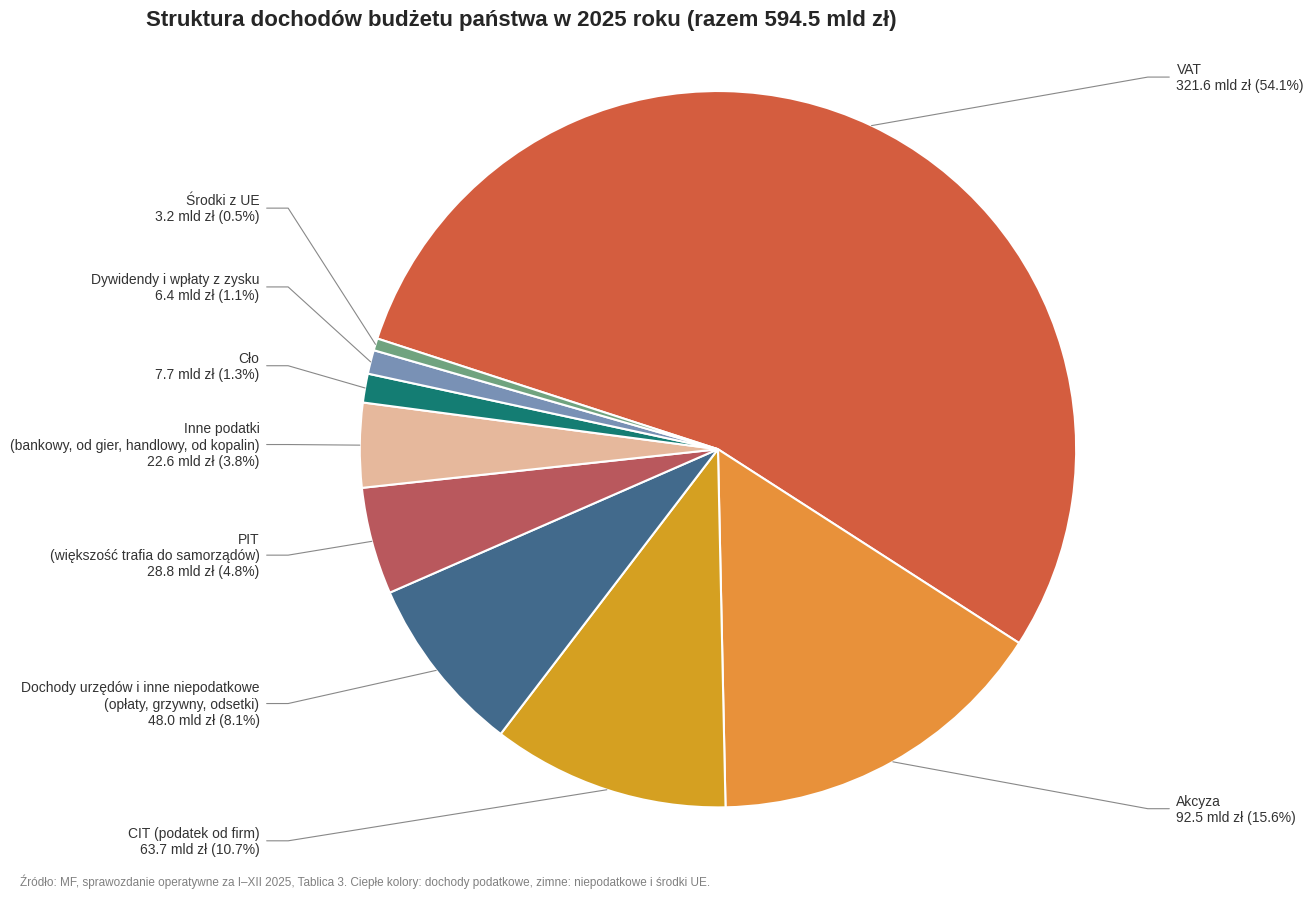

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PLIK = "raw_data_2025/20260601_Sprawozdanie_operatywne_za_styczeń_-_grudzień_2025_r.xlsx"

# 1. Wczytanie TABLICY 3 (dochody budżetu państwa, w tys. zł).
#    Tablica ma kilka bloków po 3 okresy; bierzemy kolumnę z nagłówkiem "I - XII" (cały rok).
raw = pd.read_excel(PLIK, sheet_name="TABLICA 3", header=None)
naglowek = raw.apply(lambda col: col.astype(str).str.replace(" ", "") == "I-XII")
wiersz_nagl, kol = np.argwhere(naglowek.values)[0]
blok = raw.iloc[wiersz_nagl + 1:]

def wartosc(poczatek_nazwy):
    """Wykonanie za I-XII (mld zł) dla wiersza, którego nazwa zaczyna się od podanego tekstu."""
    nazwy = blok[0].astype(str).str.strip()
    trafienia = blok[nazwy.str.startswith(poczatek_nazwy)]
    assert len(trafienia) == 1, f"nie znaleziono jednoznacznie: {poczatek_nazwy}"
    return trafienia.iloc[0, kol] / 1e6        # tys. zł -> mld zł

ogolem = wartosc("D O C H O D Y")

# 2. Rozłączne składniki dochodów (ich suma = dochody ogółem)
czesci = pd.Series({
    "VAT": wartosc("1. 1."),
    "Akcyza": wartosc("1. 2."),
    "CIT (podatek od firm)": wartosc("1. 4."),
    "PIT\n(większość trafia do samorządów)": wartosc("1. 5."),
    "Inne podatki\n(bankowy, od gier, handlowy, od kopalin)":
        wartosc("1. 3.") + wartosc("1. 6.") + wartosc("1. 7.") + wartosc("1. 8.") + wartosc("1. 9."),
    "Dywidendy i wpłaty z zysku": wartosc("2. 1."),
    "Cło": wartosc("2. 2."),
    "Dochody urzędów i inne niepodatkowe\n(opłaty, grzywny, odsetki)": wartosc("2. 3."),
    "Środki z UE": wartosc("3. Środki"),
})
assert abs(czesci.sum() - ogolem) < 0.01, "składniki nie sumują się do dochodów ogółem"
czesci = czesci.sort_values(ascending=False)    # wszystkie wycinki od największego

# 3. Kolory: dochody podatkowe w ciepłych barwach, niepodatkowe i UE w zimnych
PODATKOWE = {"VAT", "Akcyza", "CIT (podatek od firm)", "PIT\n(większość trafia do samorządów)",
             "Inne podatki\n(bankowy, od gier, handlowy, od kopalin)"}
CIEPLE = iter(["#D45D3F", "#E8913A", "#D5A021", "#B9585D", "#E6B89C"])
ZIMNE = iter(["#426A8C", "#147D73", "#7991B5", "#70A37F"])
kolory = [next(CIEPLE) if n in PODATKOWE else next(ZIMNE) for n in czesci.index]

# 4. Koło bez legendy (wszystko w podpisach na zewnątrz).
#    startangle dobrany tak, żeby małe wycinki wypadły z lewej strony, gdzie jest miejsce na podpisy.
fig, ax = plt.subplots(figsize=(13, 9))
wedges, _ = ax.pie(
    czesci, startangle=162, counterclock=False, colors=kolory,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)

# 5. Podpisy na zewnątrz z łamanymi liniami prowadzącymi
podpisy = []
for w, (nazwa, kw) in zip(wedges, czesci.items()):
    kat = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(kat), np.sin(kat)
    podpisy.append({"nazwa": nazwa, "kw": kw, "x": x, "y": y,
                    "strona": 1 if x >= 0 else -1, "y_tekst": 1.15 * y})

ODSTEP, Y_MAX = 0.22, 1.25                      # rozsuwanie podpisów, żeby nie nachodziły
for strona in (1, -1):
    grupa = sorted([p for p in podpisy if p["strona"] == strona], key=lambda p: p["y_tekst"])
    for _ in range(50):
        for a, b in zip(grupa, grupa[1:]):
            b["y_tekst"] = max(b["y_tekst"], a["y_tekst"] + ODSTEP)
        grupa[-1]["y_tekst"] = min(grupa[-1]["y_tekst"], Y_MAX)
        for a, b in zip(grupa[::-1], grupa[-2::-1]):
            b["y_tekst"] = min(b["y_tekst"], a["y_tekst"] - ODSTEP)
        grupa[0]["y_tekst"] = max(grupa[0]["y_tekst"], -Y_MAX)

for p in podpisy:
    s = p["strona"]
    x_lamanie, x_tekst = s * 1.2, s * 1.28
    ax.plot([p["x"], x_lamanie, x_tekst - s * 0.02], [p["y"], p["y_tekst"], p["y_tekst"]],
            color="#888888", lw=0.8)
    ax.text(x_tekst, p["y_tekst"],
            f"{p['nazwa']}\n{p['kw']:.1f} mld zł ({p['kw'] / ogolem * 100:.1f}%)",
            ha="left" if s == 1 else "right", va="center", fontsize=10, color="#333333")

ax.set_title(f"Struktura dochodów budżetu państwa w 2025 roku (razem {ogolem:.1f} mld zł)",
             loc="left", fontsize=16, fontweight="bold", pad=10)
ax.axis("equal")
fig.text(0.01, 0.01, "Źródło: MF, sprawozdanie operatywne za I–XII 2025, Tablica 3. "
         "Ciepłe kolory: dochody podatkowe, zimne: niepodatkowe i środki UE.",
         fontsize=8.5, color="gray")
fig.tight_layout()
fig.savefig(Path("img") / "budzet_2025_kolo_struktura_dochodow.png", dpi=180, bbox_inches="tight")
plt.show()